# 06 · Clustering experiment: k-Means (from scratch)

Implementation: `src/kmeans.py`. Unlike the classifiers, k-Means **never sees the labels**. It
only groups vectors that are close together. Afterwards we compare the groups with the true
labels to ask: *do the feature representations separate the classes on their own?*

How we score the match between clusters and labels:
* **Purity**: give each cluster its most common true label and count how many points that gets right
  (1.0 = every cluster contains a single class). Purity rises automatically with more clusters,
  so we compare it with a random-assignment baseline.
* **NMI** (normalised mutual information, 0 to 1): how much knowing the cluster tells you about the label.
* **ARI** (adjusted Rand index): agreement on which pairs of points belong together, corrected so a random clustering scores ≈ 0.

We cluster all labelled training rows (no train/validation split is needed: nothing is being predicted).

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score  # metrics only
from src.common import *
from src.plotting import *
from src.kmeans import KMeans
set_seed()

def purity(y, clusters):
    total = 0
    for c in np.unique(clusters):
        total += np.bincount(y[clusters == c]).max()
    return total / len(y)

def scores(y, clusters, seed=SEED):
    rnd = np.random.default_rng(seed).permutation(clusters)   # same cluster sizes, random membership
    return dict(purity=purity(y, clusters), purity_random=purity(y, rnd),
                nmi=normalized_mutual_info_score(y, clusters), ari=adjusted_rand_score(y, clusters))

## 1 · Sentiment: do tweets split into Negative / Neutral / Positive by themselves?

In [2]:
Xs, ys, _, _ = load_task("sentiment")
rows, s_models = [], {}
for rep, pp in (("standardized", Preprocessor("standardize")),
                ("standardized + PCA-50", Preprocessor("standardize", pca_dims=50))):
    Z = pp.fit_transform(Xs)
    for k in range(2, 11):
        km = KMeans(n_clusters=k, n_init=5, random_state=SEED).fit(Z)
        s_models[(rep, k)] = km
        rows.append(dict(representation=rep, k=k, inertia=km.inertia_, **scores(ys, km.labels_)))
sent_k = pd.DataFrame(rows)
save_table(sent_k, "kmeans_sentiment_k_sweep")
sent_k.round(4)

,representation,k,inertia,purity,purity_random,nmi,ari
0,standardized,2,8.880832e+06,0.3914,0.3351,0.0117,0.0137
1,standardized,3,8.674731e+06,0.4231,0.3392,0.0191,0.0203
2,standardized,4,8.523294e+06,0.4258,0.3412,0.0212,0.0216
3,standardized,5,8.386093e+06,0.4208,0.3449,0.0281,0.0220
4,standardized,6,8.283277e+06,0.4202,0.3448,0.0269,0.0211
5,standardized,7,8.197572e+06,0.4234,0.3449,0.0260,0.0210
6,standardized,8,8.120103e+06,0.4436,0.3445,0.0308,0.0239
7,standardized,9,8.038489e+06,0.4451,0.3452,0.0325,0.0239
8,standardized,10,7.974597e+06,0.4562,0.3459,0.0410,0.0268
9,standardized + PCA-50,2,5.174636e+06,0.3922,0.3352,0.0120,0.0141


k = 3, standardized features: how the true labels are spread over the 3 clusters
true label  Negative  Neutral  Positive
cluster                                
0                386      756       463
1               1345     1632      2052
2               2269     1612      1485

share of each cluster (rows sum to 1):
true label  Negative  Neutral  Positive
cluster                                
0              0.240    0.471     0.288
1              0.267    0.325     0.408
2              0.423    0.300     0.277


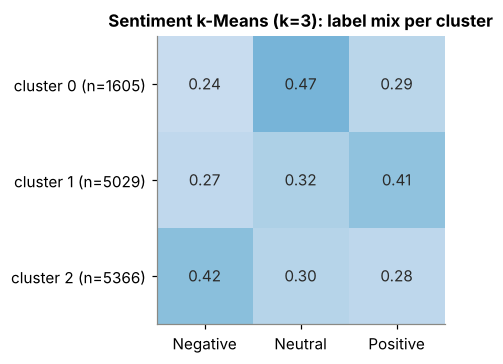

In [3]:
km3 = s_models[("standardized", 3)]
ct = pd.crosstab(pd.Series(km3.labels_, name="cluster"), pd.Series([SENTIMENT_NAMES[i] for i in ys], name="true label"))
ct = ct[SENTIMENT_NAMES]
print("k = 3, standardized features: how the true labels are spread over the 3 clusters")
print(ct)
print("\nshare of each cluster (rows sum to 1):")
print((ct.div(ct.sum(axis=1), axis=0)).round(3))
save_table(ct.reset_index(), "kmeans_sentiment_k3_crosstab")

fig, ax = plt.subplots(figsize=(4.6, 3.4))
frac = ct.div(ct.sum(axis=1), axis=0).to_numpy()
im = ax.imshow(frac, cmap=SEQ_CMAP, vmin=0, vmax=1)
ax.set_xticks(range(3)); ax.set_xticklabels(SENTIMENT_NAMES)
ax.set_yticks(range(3)); ax.set_yticklabels([f"cluster {c} (n={n})" for c, n in zip(ct.index, ct.sum(axis=1))])
for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{frac[i, j]:.2f}", ha="center", va="center", color="white" if frac[i, j] > .5 else "#2b2b2a")
ax.set_title("Sentiment k-Means (k=3): label mix per cluster"); ax.grid(False)
savefig(fig, "06_kmeans_sentiment_k3"); plt.show()

**Result: no.** With k = 3, every cluster contains plenty of all three sentiments. Purity is only
about 0.42 (random clusters of the same sizes: about 0.34) and NMI is about 0.02 (0 = no relation).
Two clusters lean slightly Negative and slightly Positive, but the largest structure in BERT
embeddings of tweets is something other than sentiment (topic, length, style…). Reducing to 50 PCA
dimensions first changes nothing. This matches notebook 01: sentiment lives in a few weak directions,
which supervised models can find (≈ 68% accuracy) but unsupervised clustering does not.

## 2 · Images: do the 50 object classes form 50 clusters?
Hellinger-transformed histograms (the representation that worked best for k-NN).

In [4]:
Xi, yi, _, _ = load_task("image")
Zi = Preprocessor("hellinger").fit_transform(Xi)
rows, i_models = [], {}
for k in (10, 25, 50, 100, 200):
    with Timer() as t:
        km = KMeans(n_clusters=k, n_init=3, max_iter=100, random_state=SEED).fit(Zi)
    i_models[k] = km
    rows.append(dict(k=k, inertia=km.inertia_, **scores(yi, km.labels_), fit_s=round(t.seconds, 1)))
    print(f"k={k}: {rows[-1]}")
img_k = pd.DataFrame(rows)
save_table(img_k, "kmeans_image_k_sweep")
img_k.round(4)

k=10: {'k': 10, 'inertia': 15562.361986150681, 'purity': np.float64(0.04605), 'purity_random': np.float64(0.0274), 'nmi': 0.031272701636500706, 'ari': 0.00678128822523978, 'fit_s': 29.4}


k=25: {'k': 25, 'inertia': 15162.66898382055, 'purity': np.float64(0.0754), 'purity_random': np.float64(0.033), 'nmi': 0.08147845368387265, 'ari': 0.016300879803751677, 'fit_s': 35.5}


k=50: {'k': 50, 'inertia': 14869.23525418748, 'purity': np.float64(0.1076), 'purity_random': np.float64(0.03675), 'nmi': 0.12292534701427335, 'ari': 0.02519201004762078, 'fit_s': 47.2}


k=100: {'k': 100, 'inertia': 14620.605922244558, 'purity': np.float64(0.1367), 'purity_random': np.float64(0.04585), 'nmi': 0.16090832360321994, 'ari': 0.02931243490864088, 'fit_s': 37.4}


k=200: {'k': 200, 'inertia': 14341.704218247438, 'purity': np.float64(0.17125), 'purity_random': np.float64(0.05695), 'nmi': 0.20013681125531185, 'ari': 0.0305365163869529, 'fit_s': 42.6}


,k,inertia,purity,purity_random,nmi,ari,fit_s
0,10,15562.3620,0.0460,0.0274,0.0313,0.0068,29.4
1,25,15162.6690,0.0754,0.0330,0.0815,0.0163,35.5
2,50,14869.2353,0.1076,0.0368,0.1229,0.0252,47.2
3,100,14620.6059,0.1367,0.0458,0.1609,0.0293,37.4
4,200,14341.7042,0.1713,0.0570,0.2001,0.0305,42.6


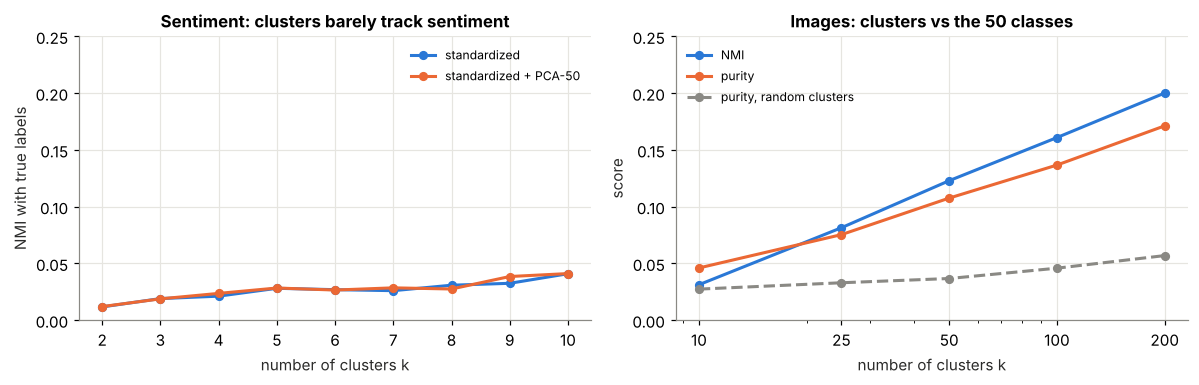

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for j, rep in enumerate(("standardized", "standardized + PCA-50")):
    r = sent_k[sent_k.representation == rep]
    axes[0].plot(r.k, r.nmi, marker="o", color=PALETTE[j], label=rep)
axes[0].set_ylim(0, 0.25)   # same scale as the image panel, so the two can be compared
axes[0].set_xlabel("number of clusters k"); axes[0].set_ylabel("NMI with true labels")
axes[0].set_title("Sentiment: clusters barely track sentiment"); axes[0].legend(fontsize=8)
axes[1].plot(img_k.k, img_k.nmi, marker="o", color=PALETTE[0], label="NMI")
axes[1].plot(img_k.k, img_k.purity, marker="o", color=PALETTE[1], label="purity")
axes[1].plot(img_k.k, img_k.purity_random, marker="o", color="#8a8984", linestyle="--", label="purity, random clusters")
axes[1].set_xscale("log"); axes[1].set_xticks(img_k.k); axes[1].set_xticklabels(img_k.k)
axes[1].set_ylim(0, 0.25)
axes[1].set_xlabel("number of clusters k"); axes[1].set_ylabel("score")
axes[1].set_title("Images: clusters vs the 50 classes"); axes[1].legend(fontsize=8)
fig.tight_layout()
savefig(fig, "06_kmeans_k_sweep"); plt.show()

**Result: only weakly.** With k = 50, a cluster's majority class covers about 11% of its images
(random clusters: about 4%). Purity and NMI keep rising as k grows to 200. That fits notebook 02's
finding that each class is made of many small groups of near-relatives rather than one big blob:
more, smaller clusters can follow those groups.

### Which classes are grouped together?
For k = 50, the "co-clustering" score of two classes is the probability that a random image of
class A and a random image of class B fall into the same cluster. High score = k-Means can't tell
them apart without labels.

In [6]:
km50 = i_models[50]
P = pd.crosstab(yi, km50.labels_).to_numpy().astype(float)
P = P / P.sum(1, keepdims=True)                     # row a: distribution of class a over clusters
S = P @ P.T                                         # S[a, b] = P(same cluster)
iu = np.triu_indices(50, k=1)
pairs = pd.DataFrame(dict(class_a=iu[0], class_b=iu[1], same_cluster_prob=S[iu]))
pairs = pairs.sort_values("same_cluster_prob", ascending=False)
save_table(pairs, "kmeans_image_coclustered_pairs")
print("most frequently co-clustered class pairs:")
print(pairs.head(10).round(3).to_string(index=False))

concentration = pd.DataFrame(dict(cls=np.arange(50), largest_cluster_share=P.max(1),
                                  self_same_cluster_prob=np.diag(S))).sort_values("largest_cluster_share", ascending=False)
save_table(concentration, "kmeans_image_class_concentration")
print("\nclasses most concentrated in one cluster:")
print(concentration.head(5).round(3).to_string(index=False))
print("\nclasses most spread out:")
print(concentration.tail(5).round(3).to_string(index=False))

most frequently co-clustered class pairs:
 class_a  class_b  same_cluster_prob
      45       48              0.110
       2        3              0.053
       2        4              0.053
      12       25              0.051
      37       39              0.049
      14       25              0.048
      20       23              0.048
      12       14              0.046
      21       23              0.044
       3        4              0.043

classes most concentrated in one cluster:
 cls  largest_cluster_share  self_same_cluster_prob
  46                  0.375                   0.163
  48                  0.365                   0.153
  13                  0.330                   0.129
  45                  0.250                   0.085
  25                  0.230                   0.082

classes most spread out:
 cls  largest_cluster_share  self_same_cluster_prob
  30                  0.070                   0.037
  35                  0.070                   0.038
  24          